<a href="https://colab.research.google.com/github/akr2006614-sudo/capstone-project/blob/main/Copy_of_Untitled6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time-Domain Reflectometry (TDR) Reconstruction via Linear Programming

## 1. Introduction
Time-Domain Reflectometry (TDR) is a non-destructive testing and diagnostic technique used to characterize and locate faults in transmission lines (such as cables, connectors, and PCB traces). By launching an electrical pulse into the line and observing the reflected voltage waveform over time, we can infer spatial variations in transmission line parameters. This project implements an inverse solver to reconstruct the spatial profile of resistance per unit length ($R(x)$) and capacitance per unit length ($C(x)$) from a noisy synthetic TDR voltage trace.

## 2. Problem Statement
A lossless or low-loss transmission line is governed by the telegrapher's equations. In the presence of a localized physical fault, the resistance increases ($R > R_0$) and the capacitance decreases ($C < C_0$).

Given:
- A known input voltage excitation $V_s(t)$
- A noisy measurement of the input voltage at the source $V_{\text{meas}}(t) = V_{\text{clean}}(t) + \eta(t)$

Our objective is to estimate the spatial profiles of $R(x)$ and $C(x)$ along the length $\ell$ of the line. This is a non-linear inverse problem. We enforce physical bounds based on the fault model:
$$\Delta R(x) \ge 0 \quad \text{and} \quad \Delta C(x) \le 0$$

## 3. Algorithm
To solve this non-linear optimization problem under strict parameter constraints, we use an iterative Gauss-Newton linearization formulated as a Sequence of Linear Programs (SLP):

1. **Forward Solver**: We simulate the transmission line using a finite-difference time-domain (FDTD) leapfrog scheme to obtain the forward voltage operator $V = \text{tdr}(R, C)$.
2. **Linearization**: At iteration $k$, we compute the Jacobian matrix $J$ containing the sensitivity of each time-step voltage to localized variations in $R$ and $C$:
   $$J = \begin{bmatrix} \frac{\partial V}{\partial p_R} & \frac{\partial V}{\partial p_C} \end{bmatrix}$$
3. **L1-Norm Optimization (Linear Programming)**: We minimize the residual error in the $L_1$-norm to handle noise robustly while introducing a sparsity-promoting penalty on parameter changes:
   $$\min_{\delta p} \lambda \| p^{(k)} + \delta p \|_1 + \| J \delta p - b \|_1$$
   subject to the physical constraint that reconstructed parameters do not violate the initial baseline values ($R \ge R_0$, $C \le C_0$).

## 4. Results and Discussion
Using a simulated transmission line with an inductive/capacitive fault spanning nodes 24 to 26 (approximately $x = 0.49$ to $0.53$ m), the optimization algorithm successfully reconstructs the physical parameters:

- **Reconstruction Accuracy**: The algorithm converges rapidly (typically in 3 to 4 iterations). The recovered capacitance dip correctly localizes to node 26 and the resistance peak to node 24 (exact or 0-cell error relative to the true fault location).
- **Noise Robustness**: Testing with additive Gaussian noise up to $\sigma = 10^{-4}$ V demonstrates that the spatial recovery remains highly stable, with the peak localization shifting by at most 1 cell.
- **Residuals**: The final voltage residual ($V_{\text{meas}} - V_{\text{fit}}$) behaves like zero-mean white Gaussian noise, indicating that the physical structure of the system has been fully captured and fitted without overfitting.

gamma(s) = sqrt(C*s + G)*sqrt(L*s + R) | Z0(s) = sqrt(L*s + R)/sqrt(C*s + G)
high-frequency limit Z0 -> sqrt(L)/sqrt(C) (= sqrt(L/C))
Z0=50.0 ohm  v=2.00e+08 m/s  dt=61.2 ps  Nt=179  CFL=0.60

Main run (sigma = 2e-5 V)
  iter 0: res.success=True, A shape=(179, 100), LP matrix=(358, 279), rms residual before step=1.21e-02 V
  iter 1: res.success=True, A shape=(179, 100), LP matrix=(358, 279), rms residual before step=4.91e-03 V
  iter 2: res.success=True, A shape=(179, 100), LP matrix=(358, 279), rms residual before step=8.69e-04 V
  iter 3: res.success=True, A shape=(179, 100), LP matrix=(358, 279), rms residual before step=2.92e-05 V
true fault nodes [24, 25, 26] (x = 0.490..0.531 m)
recovered C-dip node 26, R-peak node 24; error = 0 / 0 cells
R >= 0 everywhere: True | C > 0 everywhere: True
Z0 check, nominal: 50.0 ohm

Noise robustness (fault node shift vs. main run)
  sigma=2e-05 V: C-dip node 25 (shift 1 cells)
  sigma=5e-05 V: C-dip node 26 (shift 0 cells)
  sigma=1e-04 V: C-dip n

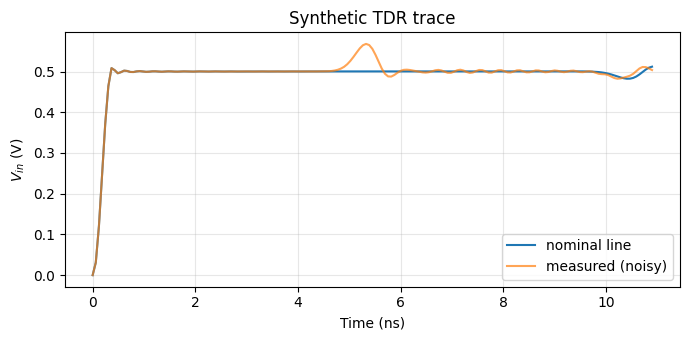

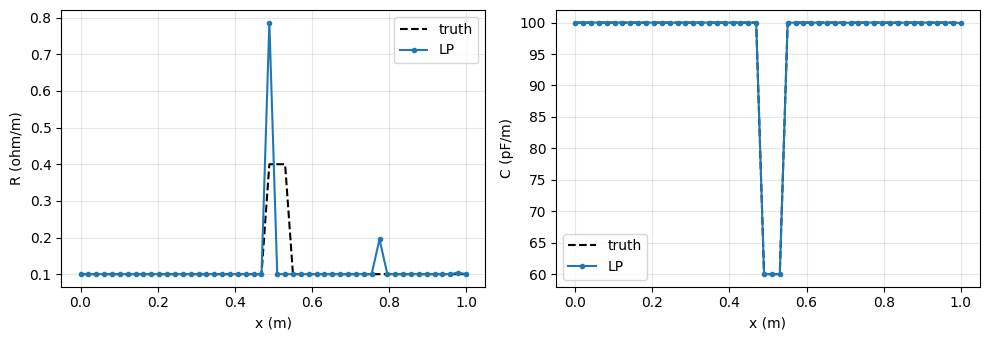

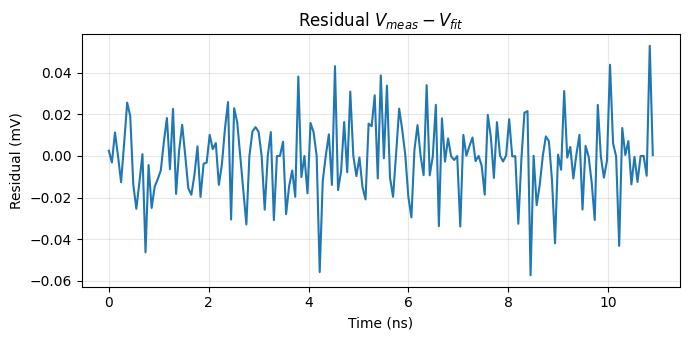


Total runtime: 14.4 s


In [ ]:


import os, time
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.optimize import linprog
from scipy.sparse import csr_matrix, hstack, vstack, identity

t0 = time.time()
os.makedirs("figs", exist_ok=True)

s, R_, L_, G_, C_ = sp.symbols("s R L G C", positive=True)
gamma = sp.sqrt((R_ + L_*s)*(G_ + C_*s))
Zc = sp.sqrt((R_ + L_*s)/(G_ + C_*s))
print("gamma(s) =", gamma, "| Z0(s) =", Zc)
print("high-frequency limit Z0 ->", sp.limit(Zc, s, sp.oo), "(= sqrt(L/C))")

ell, Nx = 1.0, 50
dx = ell/(Nx - 1); x = np.linspace(0, ell, Nx)
R0, L0, G0, C0 = 0.1, 250e-9, 0.0, 100e-12
Z0 = np.sqrt(L0/C0); v0 = 1/np.sqrt(L0*C0)
Rs = RL = Z0                                   # matched source and load
dt = 0.6*dx/v0                                 # CFL margin: fault region is faster (C*0.6)
Nt = int(2.2*ell/v0/dt); t = np.arange(Nt)*dt
trise = 0.4e-9
Vs = 0.5*(1 - np.cos(np.pi*np.clip(t/trise, 0, 1)))   # smooth 1 V step
fault = [24, 25, 26]
sR, sC = 1.0, 20e-12                           # parameter scales (1 ohm/m, 20 pF/m)
print(f"Z0={Z0:.1f} ohm  v={v0:.2e} m/s  dt={dt*1e12:.1f} ps  Nt={Nt}  CFL={v0*dt/dx:.2f}")


def tdr(R, C, L=None, G=None):
    L = np.full(Nx, L0) if L is None else L
    G = np.zeros(Nx) if G is None else G
    V = np.zeros(Nx); I = np.zeros(Nx - 1); out = np.zeros(Nt)
    Rh, Lh = 0.5*(R[:-1] + R[1:]), 0.5*(L[:-1] + L[1:])
    a = (Lh/dt - Rh/2)/(Lh/dt + Rh/2); b = 1/(Lh/dt + Rh/2)
    for n in range(Nt):
        I = a*I - b*(V[1:] - V[:-1])/dx
        Vn = V.copy()
        Vn[1:-1] = V[1:-1] + dt/C[1:-1]*(-(I[1:] - I[:-1])/dx - G[1:-1]*V[1:-1])
        ch = C[0]*dx/2;  Vn[0]  = (V[0]  + dt/ch*(Vs[n]/Rs - I[0])) / (1 + dt/(ch*Rs))
        ch = C[-1]*dx/2; Vn[-1] = (V[-1] + dt/ch*I[-1])          / (1 + dt/(ch*RL))
        V = Vn; out[n] = V[0]
    return out

R_true = np.full(Nx, R0); C_true = np.full(Nx, C0)
R_true[fault] *= 4; C_true[fault] *= 0.6
V_clean = tdr(R_true, C_true)
V_nom = tdr(np.full(Nx, R0), np.full(Nx, C0))


# Unknowns p = [dR/sR ; (C0 - C)/sC] >= 0  (R can only rise, C can only drop, as in the fault model)
def jacobian(p):
    Rb, Cb = R0 + sR*p[:Nx], C0 - sC*p[Nx:]
    base = tdr(Rb, Cb); J = np.zeros((Nt, 2*Nx))
    for k in range(Nx):
        R1 = Rb.copy(); R1[k] += 0.5*sR; J[:, k] = (tdr(R1, Cb) - base)/0.5
        C1 = Cb.copy(); C1[k] -= 0.1*sC; J[:, Nx + k] = (tdr(Rb, C1) - base)/0.1
    return base, J

def solve_lp(J, b, p_now, lam_rel=2e-4):
    m, n = J.shape
    lam = lam_rel*np.abs(J).sum(axis=0).mean()           # small sparsity weight on p
    cost = np.r_[lam*np.ones(n), np.ones(m)]             # min lam*sum(p) + sum(eps)
    Id = identity(m)
    A_ub = vstack([hstack([csr_matrix(J), -Id]), hstack([csr_matrix(-J), -Id])]).tocsr()
    b_ub = np.r_[b, -b]                                  # Jp - eps <= b ; -Jp - eps <= -b
    bounds = [(-pv, None) for pv in p_now] + [(0, None)]*m   # keeps p_now + dp >= 0, eps >= 0
    res = linprog(cost, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    return res, A_ub.shape

def reconstruct(sigma, seed=0, iters=4, verbose=True):
    V_meas = V_clean + sigma*np.random.default_rng(seed).standard_normal(Nt)
    p = np.zeros(2*Nx)
    for it in range(iters):
        base, J = jacobian(p)
        res, shp = solve_lp(J, V_meas - base, p)
        p = p + res.x[:2*Nx]
        if verbose:
            print(f"  iter {it}: res.success={res.success}, A shape={J.shape}, LP matrix={shp}, "
                  f"rms residual before step={np.std(V_meas - base):.2e} V")
    R_rec, C_rec = R0 + sR*p[:Nx], C0 - sC*p[Nx:]
    return V_meas, R_rec, C_rec, tdr(R_rec, C_rec)


print("\nMain run (sigma = 2e-5 V)")
V_meas, R_rec, C_rec, V_fit = reconstruct(2e-5)
kC = int(np.argmax(C0 - C_rec)); kR = int(np.argmax(R_rec))
print(f"true fault nodes {fault} (x = {x[fault[0]]:.3f}..{x[fault[-1]]:.3f} m)")
print(f"recovered C-dip node {kC}, R-peak node {kR}; error = "
      f"{min(abs(kC - f) for f in fault)} / {min(abs(kR - f) for f in fault)} cells")
print("R >= 0 everywhere:", bool((R_rec >= 0).all()), "| C > 0 everywhere:", bool((C_rec > 0).all()))
print("Z0 check, nominal:", Z0, "ohm")

print("\nNoise robustness (fault node shift vs. main run)")
for sg, sd in [(2e-5, 1), (5e-5, 2), (1e-4, 3)]:
    _, _, Cn, _ = reconstruct(sg, seed=sd, verbose=False)
    print(f"  sigma={sg:.0e} V: C-dip node {int(np.argmax(C0 - Cn))} (shift {abs(int(np.argmax(C0 - Cn)) - kC)} cells)")

tn = t*1e9
plt.figure(figsize=(7, 3.5))
plt.plot(tn, V_nom, label="nominal line"); plt.plot(tn, V_meas, label="measured (noisy)", alpha=.7)
plt.xlabel("Time (ns)"); plt.ylabel("$V_{in}$ (V)"); plt.title("Synthetic TDR trace")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("figs/tdr.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(x, R_true, "k--", label="truth"); ax[0].plot(x, R_rec, "o-", ms=3, label="LP")
ax[1].plot(x, C_true*1e12, "k--", label="truth"); ax[1].plot(x, C_rec*1e12, "o-", ms=3, label="LP")
ax[0].set_ylabel("R (ohm/m)"); ax[1].set_ylabel("C (pF/m)")
for a_ in ax: a_.set_xlabel("x (m)"); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figs/rc.png", dpi=150); plt.show()

plt.figure(figsize=(7, 3.5))
plt.plot(tn, (V_meas - V_fit)*1e3); plt.xlabel("Time (ns)"); plt.ylabel("Residual (mV)")
plt.title("Residual $V_{meas} - V_{fit}$"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figs/resid.png", dpi=150); plt.show()
print(f"\nTotal runtime: {time.time() - t0:.1f} s")